In [1]:
!pip install git+https://github.com/RocketPy-Team/RocketPy.git@develop


  Cloning https://github.com/RocketPy-Team/RocketPy.git (to revision develop) to c:\users\arthu\appdata\local\temp\pip-req-build-vff329zv


  ERROR: Error [WinError 2] O sistema não pode encontrar o arquivo especificado while executing command git version

[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Cannot find command 'git' - do you have 'git' installed and in your PATH?


In [2]:
from rocketpy import Environment, Flight, Rocket, SolidMotor


In [3]:
%config InlineBackend.figure_formats = ['svg']
%matplotlib inline


In [4]:
# Configura as condições do local e data de lançamento
env = Environment(
    latitude=-21.942386,
    longitude=-48.952058,
    elevation=489
)


In [5]:
from datetime import datetime, timedelta
from rocketpy import Environment

tomorrow = datetime.now() + timedelta(days=0, hours=-13, minutes=-30)

env.set_date(
    (tomorrow.year, tomorrow.month, tomorrow.day, 12)
)  # Hora em UTC


In [6]:
# Instala netCDF4 (necessário para acessar dados GFS via OpenDAP no Colab)
!pip install -q netCDF4



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


c:\Users\arthu\OneDrive\Desktop\treinee\.venv\Lib\site-packages\rocketpy\environment\tools.py:553: UserWarning: Exact chosen launch time is not available in the provided file, using 2026-10-29 03:00:00 UTC instead.
  warnings.warn(


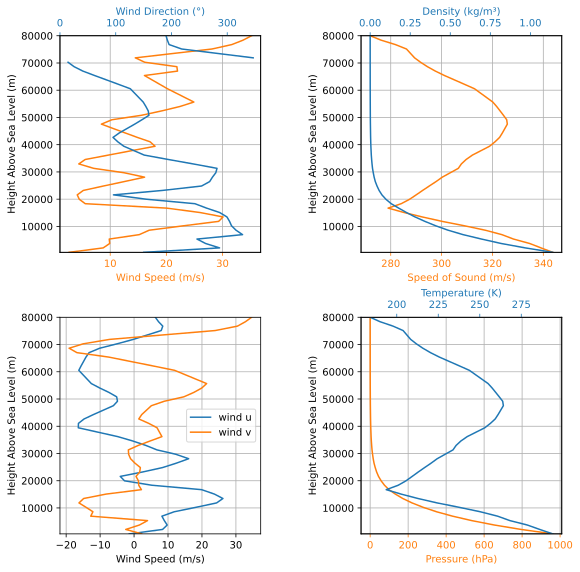


Gravity Details

Acceleration of gravity at surface level:    9.7861 m/s²
Acceleration of gravity at  79.609 km (ASL): 9.5464 m/s²


Launch Site Details

Launch Date: 2026-10-29 04:04:01 UTC
Launch Site Latitude: -21.94239°
Launch Site Longitude: -48.95206°
Reference Datum: SIRGAS2000
Launch Site UTM coordinates: 91665.69 W    7568281.98 S
Launch Site UTM zone: 23K
Launch Site Surface Elevation: 475.5 m


Atmospheric Model Details

Atmospheric Model Type: forecast
forecast Maximum Height: 79.609 km

Surface Atmospheric Conditions

Surface Wind Speed: 2.56 m/s
Surface Wind Direction: 150.96°
Surface Wind Heading: 330.96°
Surface Pressure: 962.27 hPa
Surface Temperature: 293.95 K
Surface Air Density: 1.140 kg/m³
Surface Speed of Sound: 343.70 m/s


Earth Model Details

Earth Radius at Launch site: 6375.17 km
Semi-major Axis: 6378.14 km
Semi-minor Axis: 6356.75 km
Flattening: 0.0034


Atmospheric Model Plots



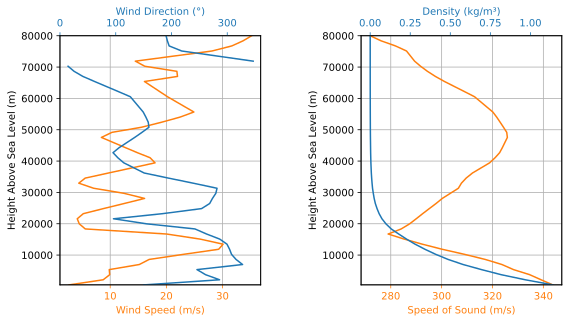


✅ Modelo atmosférico GFS carregado com sucesso!


In [7]:
# Modelo atmosférico GFS via NOAA
# O servidor NOAA pode estar indisponível no Colab (bloqueio de IP ou instabilidade).
# O RocketPy faz retry infinito internamente, então usamos signal.alarm como timeout.
# Se não carregar em 90s, faz fallback para atmosfera padrão (ISA).
import os, signal

GFS_TIMEOUT = 90  # segundos

def _gfs_timeout_handler(signum, frame):
    raise TimeoutError("Tempo limite excedido ao carregar modelo GFS do NOAA")

try:
    if os.name != 'nt':  # Linux/Colab
        signal.signal(signal.SIGALRM, _gfs_timeout_handler)
        signal.alarm(GFS_TIMEOUT)

    env_gfs = Environment(
    latitude=-21.942386,
    longitude=-48.952058,
    elevation=489,
    date=tomorrow
    )
    env_gfs.set_atmospheric_model(type="forecast", file="GFS")

    if os.name != 'nt':
        signal.alarm(0)  # Cancela o alarme

    env_gfs.plots.atmospheric_model()
    env_gfs.info()
    env = env_gfs
    print("\n✅ Modelo atmosférico GFS carregado com sucesso!")

except Exception as e:
    if os.name != 'nt':
        signal.alarm(0)  # Garante que o alarme é cancelado
    print(f"\n⚠️ Não foi possível carregar o modelo GFS: {e}")
    print("Usando atmosfera padrão (ISA - International Standard Atmosphere).")
    print("A simulação continuará normalmente, mas sem dados meteorológicos reais.\n")


In [8]:
# ------------------------- MOTOR -------------------------
Jorge2grãos = SolidMotor(
    thrust_source='Jorge triturado_Campeao.eng',
    burn_time=1.2314,
    dry_mass=0.810,
    dry_inertia=(0.006, 0.006, 0.0002526),
    center_of_dry_mass_position=0.198,
    nozzle_position=0,
    nozzle_radius=0.0073,
    throat_radius=0.0029,
    grain_number=2,
    grain_density=1841,
    grain_outer_radius=0.0195,
    grain_initial_inner_radius=0.0068,
    grain_initial_height=0.076,
    grain_separation=0,
    grains_center_of_mass_position=0.156,
    coordinate_system_orientation="nozzle_to_combustion_chamber"
)


Nozzle Details
Nozzle Radius: 0.0073 m
Nozzle Throat Radius: 0.0029 m

Grain Details
Number of Grains: 2
Grain Spacing: 0 m
Grain Density: 1841 kg/m3
Grain Outer Radius: 0.0195 m
Grain Inner Radius: 0.0068 m
Grain Height: 0.076 m
Grain Volume: 0.000 m3
Grain Mass: 0.147 kg

Motor Details
Total Burning Time: 1.2314 s
Total Propellant Mass: 0.294 kg
Structural Mass Ratio: 0.734
Average Propellant Exhaust Velocity: 1184.998 m/s
Average Thrust: 282.569 N
Maximum Thrust: 315.4027 N at 0.7424 s after ignition.
Total Impulse: 347.956 Ns



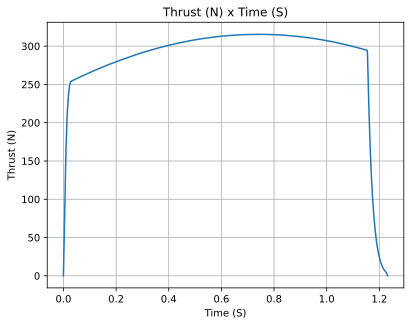

In [9]:
Jorge2grãos.info()


In [10]:
# ------------------------- FOGUETE -------------------------
Zeze060725 = Rocket(
    radius=0.032,
    mass=1.990,
    inertia=(0.244, 0.244, 0.0022),
    power_off_drag='Dragcurve_Mach_OFF.csv',
    power_on_drag='Dragcurve_Mach_ON.csv',
    center_of_mass_without_motor=0.623,
    coordinate_system_orientation="nose_to_tail"
)


In [11]:

# A 'position' é a distância (em metros) da ponta da ogiva até a saída do bocal do motor.
Zeze060725.add_motor(Jorge2grãos, position=1.13)


In [12]:
# Adiciona a Ogiva ao foguete
ogiva = Zeze060725.add_nose(
    length=0.180,
    kind='ogive',
    power=1,
    position=0
)

# Adiciona as Aletas ao foguete
aletas = Zeze060725.add_trapezoidal_fins(
    n=4,
    root_chord=0.07,
    tip_chord=0.03,
    span=0.09,
    position=0.985,
    cant_angle=0,
)

# Adiciona uma Cauda/Transição
cauda = Zeze060725.add_tail(
    top_radius=0.032,
    bottom_radius=0.02,
    length=0.0757,
    position=1.055
)

#Adiciona o rial button
Zeze060725.set_rail_buttons(0.52, 0.985)


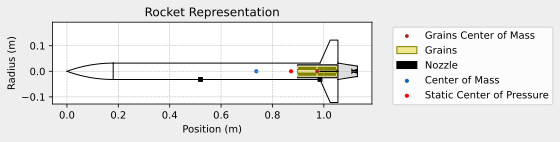

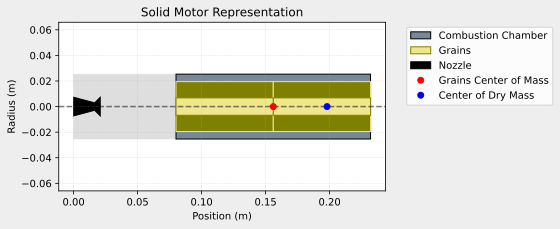

In [13]:
# Verificando a representação do foguete
Zeze060725.plots.draw()
Jorge2grãos.plots.draw()



Inertia Details

Rocket Mass: 1.990 kg (without motor)
Rocket Dry Mass: 2.800 kg (with unloaded motor)
Rocket Loaded Mass: 3.094 kg
Rocket Structural Mass Ratio: 0.905
Rocket Inertia (with unloaded motor) 11: 0.305 kg*m2
Rocket Inertia (with unloaded motor) 22: 0.305 kg*m2
Rocket Inertia (with unloaded motor) 33: 0.002 kg*m2
Rocket Inertia (with unloaded motor) 12: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 13: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 23: 0.000 kg*m2

Geometrical Parameters

Rocket Maximum Radius: 0.032 m
Rocket Frontal Area: 0.003217 m2

Rocket Distances
Rocket Center of Dry Mass - Center of Mass without Motor: 0.089 m
Rocket Center of Dry Mass - Nozzle Exit: 0.418 m
Rocket Center of Dry Mass - Center of Propellant Mass: 0.262 m
Rocket Center of Mass - Rocket Loaded Center of Mass: 0.025 m


Aerodynamics Lift Coefficient Derivatives

Nose Cone Lift Coefficient Derivative: 2.000/rad
Fins Lift Coefficient Derivative: 12.894/rad
Tail Lift Coefficient Deriv

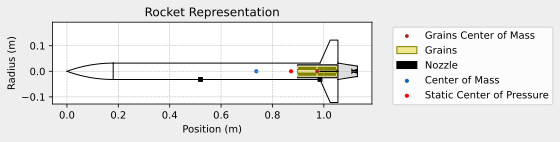


Mass Plots
----------------------------------------


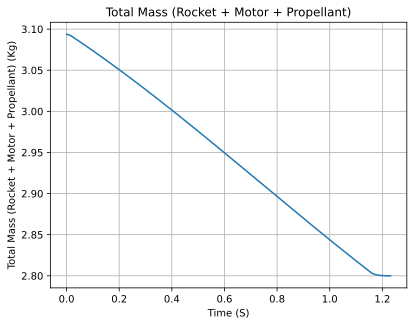

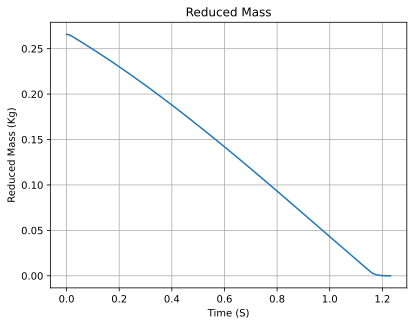


Aerodynamics Plots
----------------------------------------
Drag Plots
--------------------


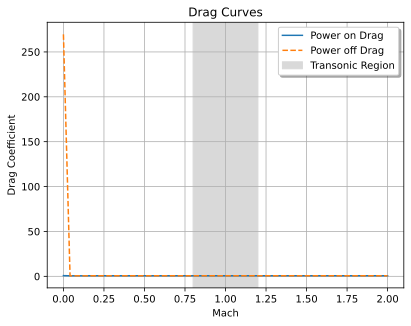


Stability Plots
--------------------


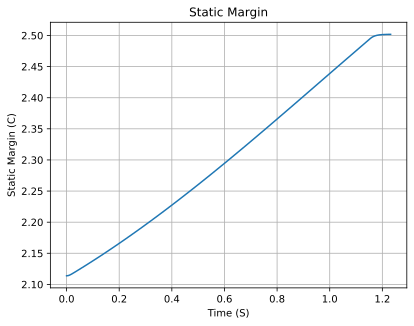

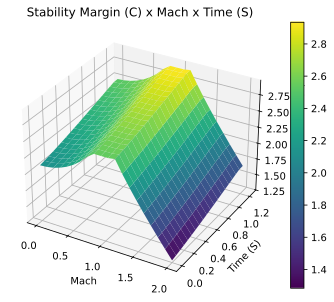


Thrust-to-Weight Plot
----------------------------------------


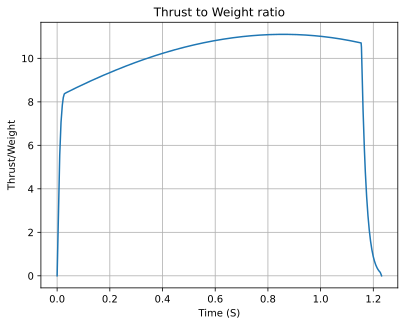

In [14]:
Zeze060725.all_info()


In [15]:
# ------------------------- SISTEMA DE RECUPERAÇÃO -------------------------

paraquedas = Zeze060725.add_parachute(
    "EVA-Mark.09 v1",
    cd_s=0.8115,
    trigger="apogee",
    sampling_rate=500,
    lag=1.5,
    noise=(0, 0.1, 0.5)
)


In [16]:
main_flight = Flight(
    rocket=Zeze060725, environment=env, rail_length=4, inclination=85, heading=330
)



Initial Conditions

Initial time: 0.000 s
Position - x: 0.00 m | y: 0.00 m | z: 475.52 m
Velocity - Vx: 0.00 m/s | Vy: 0.00 m/s | Vz: 0.00 m/s
Attitude (quaternions) - e0: 0.991 | e1: -0.035 | e2: -0.027 | e3: -0.130
Euler Angles - Spin φ : -45.00° | Nutation θ: -5.00° | Precession ψ: 30.00°
Angular Velocity - ω1: 0.00 rad/s | ω2: 0.00 rad/s | ω3: 0.00 rad/s
Initial Stability Margin: 2.114 c


Surface Wind Conditions

Frontal Surface Wind Speed: 2.54 m/s
Lateral Surface Wind Speed: 0.07 m/s


Launch Rail

Launch Rail Length: 4 m
Launch Rail Inclination: 85.00°
Launch Rail Heading: 330.00°


Rail Departure State

Rail Departure Time: 0.306 s
Rail Departure Velocity: 23.599 m/s
Rail Departure Stability Margin: 2.200 c
Rail Departure Angle of Attack: 6.259°
Rail Departure Thrust-Weight Ratio: 9.851
Rail Departure Reynolds Number: 9.442e+04


Burn out State

Burn out time: 1.231 s
Altitude at burn out: 540.349 m (ASL) | 64.825 m (AGL)
Rocket speed at burn out: 104.147 m/s
Freestream veloc

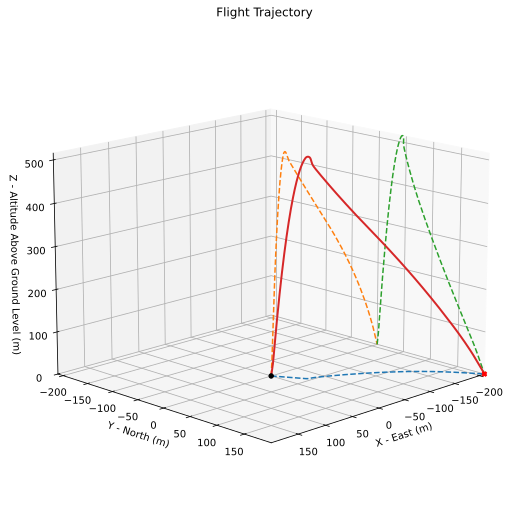



Trajectory Kinematic Plots



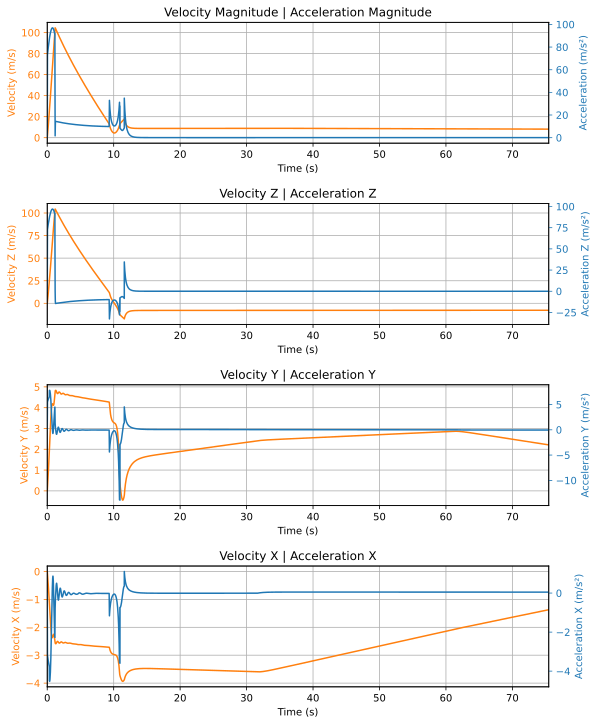



Angular Position Plots



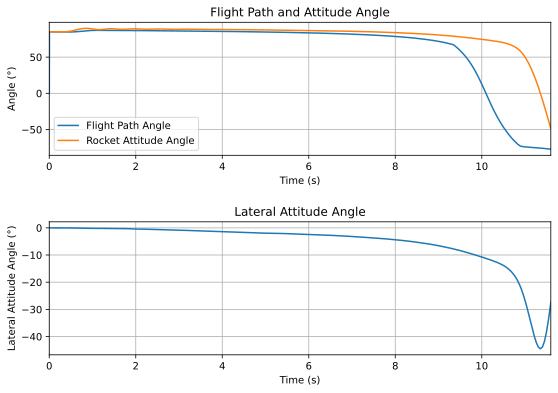



Path, Attitude and Lateral Attitude Angle Plots



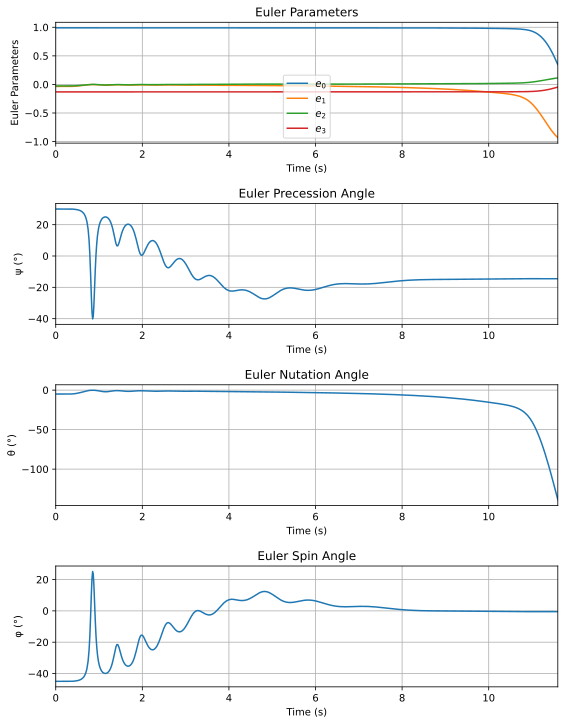



Trajectory Angular Velocity and Acceleration Plots



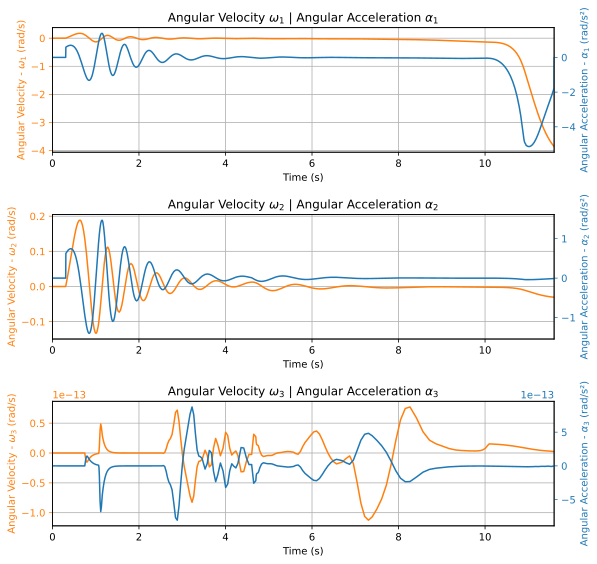



Aerodynamic Forces Plots



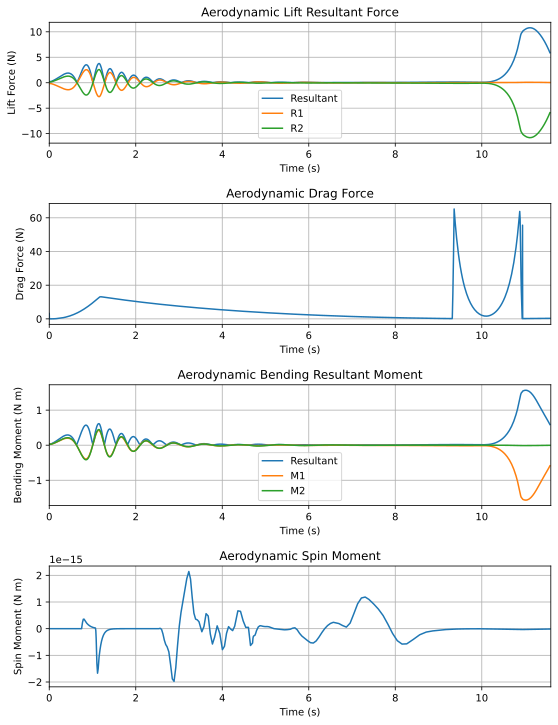

Rail button height not defined. Skipping bending moment plots.




Rail Buttons Bending Moments Plots



Rail Buttons Forces Plots



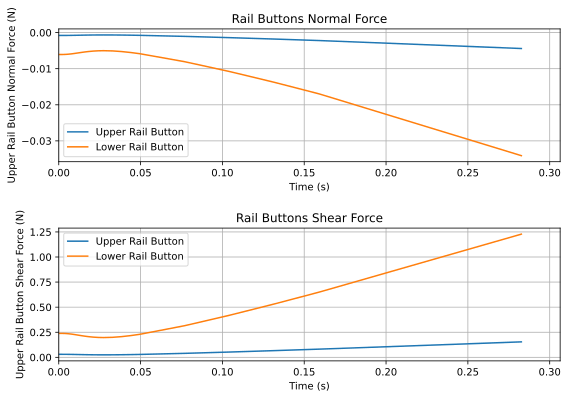



Trajectory Energy Plots



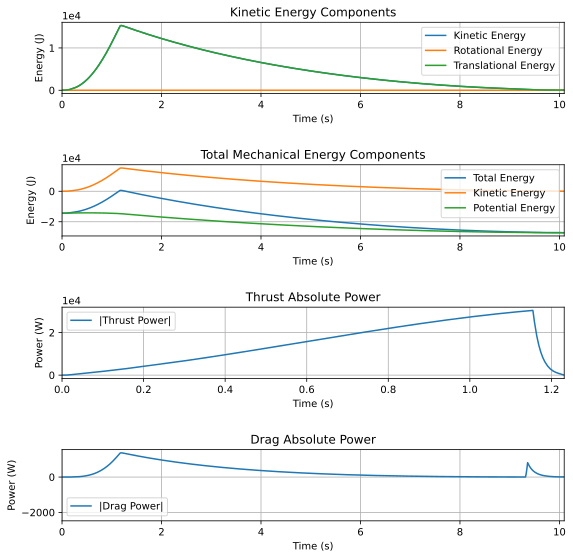



Trajectory Fluid Mechanics Plots



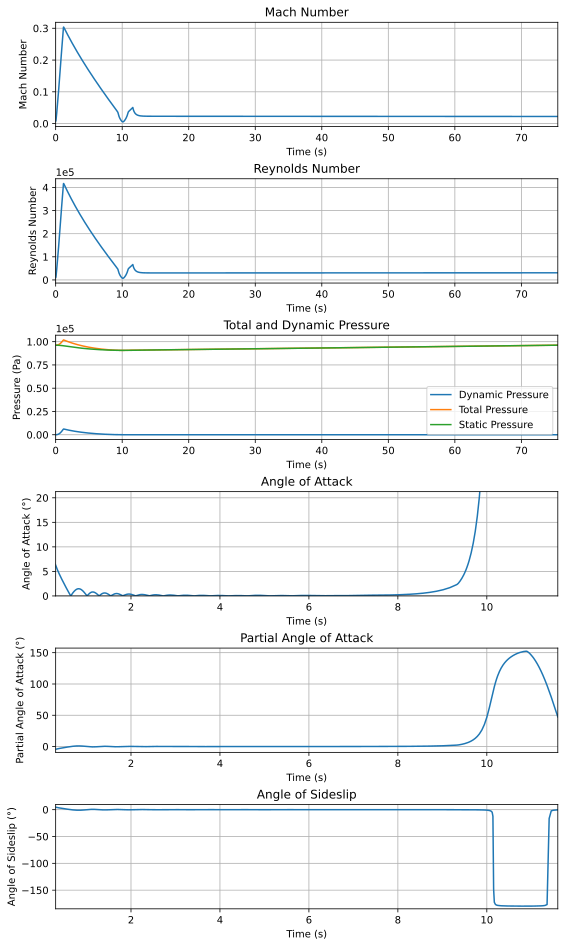



Trajectory Stability and Control Plots



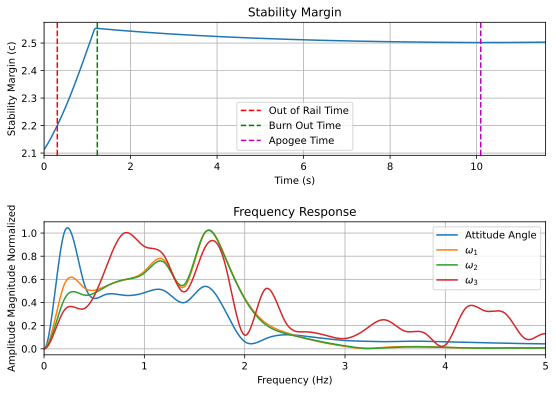



Rocket and Parachute Pressure Plots



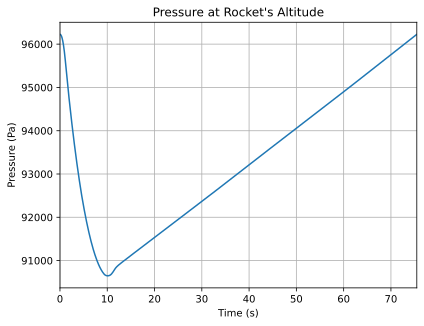

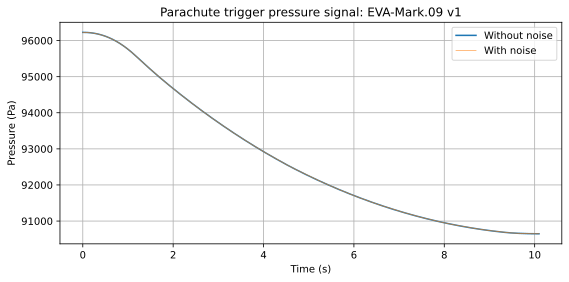

In [17]:
main_flight.all_info()


Simulando foguete com margem estática de 1.746->2.134 c


c:\Users\arthu\OneDrive\Desktop\treinee\.venv\Lib\site-packages\rocketpy\mathutils\_calc\polation_1d.py:119: RuntimeWarning: divide by zero encountered in divide
  self._slopes = np.diff(self._y) / np.diff(self._x)


Simulando foguete com margem estática de 3.462->3.850 c


c:\Users\arthu\OneDrive\Desktop\treinee\.venv\Lib\site-packages\rocketpy\mathutils\_calc\polation_1d.py:119: RuntimeWarning: invalid value encountered in divide
  self._slopes = np.diff(self._y) / np.diff(self._x)


Simulando foguete com margem estática de 5.177->5.565 c
Simulando foguete com margem estática de 6.893->7.281 c
Simulando foguete com margem estática de 8.608->8.996 c
Simulando foguete com margem estática de 10.324->10.712 c
Simulando foguete com margem estática de 12.039->12.427 c


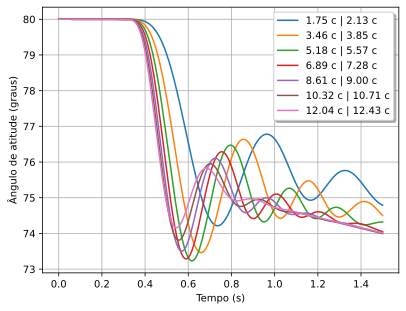

In [18]:
# Classe auxiliar
import copy
from rocketpy import Function, Environment, Flight

# Preparar uma cópia do foguete
Zeze_2 = copy.deepcopy(Zeze060725)

# Preparar a classe Environment
custom_env = Environment()
custom_env.set_atmospheric_model(type="custom_atmosphere", wind_v=-5)

# Simular diferentes margens estáticas variando a posição das aletas
simulation_results = []

# Armazena as aletas originais e as remove para o teste
# Guardamos a posição original para re-inserir depois
original_fins_pos = Zeze_2.aerodynamic_surfaces[-1].position
original_fins = Zeze_2.aerodynamic_surfaces.pop(-1)

for factor in [-0.5, -0.3, -0.1, 0.1, 0.3, 0.5, 0.7]:
    # Remove as aletas temporárias da iteração anterior se existirem
    if hasattr(Zeze_2, '_temp_fins'):
        try:
            Zeze_2.aerodynamic_surfaces.remove(Zeze_2._temp_fins)
        except (ValueError, AttributeError):
            pass

    # Adiciona novas aletas na posição variada
    fin_set = Zeze_2.add_trapezoidal_fins(
        n=4,
        root_chord=0.120,
        tip_chord=0.040,
        span=0.100,
        position=1.26 + factor,
    )
    Zeze_2._temp_fins = fin_set

    print(
        "Simulando foguete com margem estática de {:1.3f}->{:1.3f} c".format(
            Zeze_2.static_margin(0),
            Zeze_2.static_margin(Zeze_2.motor.burn_out_time),
        )
    )

    test_flight = Flight(
        rocket=Zeze_2,
        environment=custom_env,
        rail_length=4,
        inclination=80,
        heading=90,
        max_time_step=0.01,
        max_time=180,
        terminate_on_apogee=False,
        verbose=False,
    )

    simulation_results += [
        (
            test_flight.attitude_angle,
            "{:1.2f} c | {:1.2f} c".format(
                Zeze_2.static_margin(0),
                Zeze_2.static_margin(test_flight.t_final),
            ),
        )
    ]

# Remove a última aleta temporária
if hasattr(Zeze_2, '_temp_fins'):
    Zeze_2.aerodynamic_surfaces.remove(Zeze_2._temp_fins)
    del Zeze_2._temp_fins

# CORREÇÃO: Passa a posição original necessária para o método add()
Zeze_2.aerodynamic_surfaces.add(original_fins, original_fins_pos)

Function.compare_plots(
    simulation_results,
    lower=0,
    upper=1.5,
    xlabel="Tempo (s)",
    ylabel="Ângulo de atitude (graus)",
)

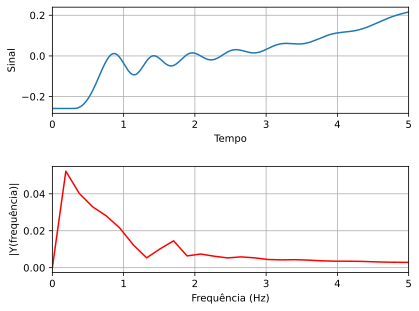

In [19]:
import matplotlib.pyplot as plt
import numpy as np

# Simular os primeiros 5 segundos de voo
flight = Flight(
    rocket=Zeze060725,
    environment=env,
    rail_length=4,
    inclination=80,
    heading=90,
    max_time_step=0.01,
    max_time=5,
)

# Realizar uma análise de Fourier
Fs = 100.0
# taxa de amostragem
Ts = 1.0 / Fs
# intervalo de amostragem
# Get time and attitude angle data from the flight results
solution = np.array(flight.solution) # Convert the solution to a NumPy array
t = solution[:, 0] # Time is in the first column of the solution
y = np.degrees(solution[:, 7]) # Attitude angle is in the 8th column, convert from radians to degrees
# Ensure t and y have the same length for FFT
min_len = min(len(t), len(y))
t = t[:min_len]
y = y[:min_len]

# Perform Fourier analysis only if there's enough data
if len(y) > 0:
    y_mean = np.mean(y)
    y_detrended = y - y_mean

    n = len(y_detrended)  # comprimento do sinal
    k = np.arange(n)
    T = n / Fs
    frq = k / T  # faixa de frequência de dois lados
    frq = frq[range(n // 2)]  # faixa de frequência de um lado
    Y = np.fft.fft(y_detrended) / n  # cálculo e normalização da FFT
    Y = Y[range(n // 2)]

    # Criar o gráfico
    fig, ax = plt.subplots(2, 1)
    ax[0].plot(t, y_detrended)
    ax[0].set_xlabel("Tempo")
    ax[0].set_ylabel("Sinal")
    ax[0].set_xlim((0, min(5, t[-1] if len(t) > 0 else 5))) # Adjust xlim based on actual flight time
    ax[0].grid()
    ax[1].plot(frq, abs(Y), "r")  # plotando o espectro
    ax[1].set_xlabel("Frequência (Hz)")
    ax[1].set_ylabel("|Y(frequência)|")
    ax[1].set_xlim((0, 5))
    ax[1].grid()
    plt.subplots_adjust(hspace=0.5)
    plt.show()
else:
    print("Not enough data to perform Fourier analysis.")

In [20]:
from rocketpy.simulation import FlightDataExporter

FlightDataExporter(main_flight).export_kml(
    file_name="ZEZE LASC 2026",
    extrude=True,
    altitude_mode="relative_to_ground",
)